# Triathlon Performance & Survey Analysis
**Regression, visualization, and responsible interpretation**

This analysis completes six original exercise topics: a swim/run scatterplot, two finish-time regressions, a model comparison, a survey comparison, and an ethics reflection. The underlying course is completed; this version makes the retained notebook reproducible and suitable for public review.

The race data contain 1,105 female finishers at Lake Placid in 2018–2019. Times are measured in minutes. A separate class-survey example examines employment and phone contact counts. The two datasets are analyzed separately.

Run all cells in order. Data snapshots are included; no database credentials or live service are needed. Only fields used in the analysis are retained. Names, bib numbers, survey timestamps, and other personal fields are excluded.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data').is_dir():
    raise FileNotFoundError('Run this notebook from the repository root.')
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
BLUE, ORANGE = '#2563a6', '#d66a32'

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def fit_time(data, predictor):
    return sm.OLS(data['OverallTime'], sm.add_constant(data[[predictor]], has_constant='add')).fit()

race = pd.read_csv(ROOT / 'data/ironman_2018_2019.csv')
time_columns = ['SwimTime', 'BikeTime', 'RunTime', 'OverallTime']
assert len(race) == 1105 and set(race['Year']) == {2018, 2019}
assert race[time_columns].notna().all().all()
assert (race[time_columns] > 0).all().all()
assert (race['OverallTime'] >= race[['SwimTime','BikeTime','RunTime']].sum(axis=1) - 1e-5).all()
display(race.groupby('Year').size().rename('finishers').to_frame())
display(race[time_columns].describe().round(2))

,finishers
Year,
2018,587
2019,518


,SwimTime,BikeTime,RunTime,OverallTime
count,1105.00,1105.00,1105.00,1105.00
mean,82.58,441.30,319.30,860.61
std,11.62,44.34,47.37,93.79
min,53.37,304.73,187.52,558.82
25%,74.68,410.12,285.38,793.05
50%,81.70,441.83,318.80,864.50
75%,90.02,475.27,356.15,939.13
max,123.65,533.82,432.75,1018.97


## 1. Swimming time and running time
Plot swim time on the horizontal axis and run time on the vertical axis. Each point represents a finisher; colors distinguish race years. This is a descriptive association rather than evidence that changing swim time causes a change in run time.

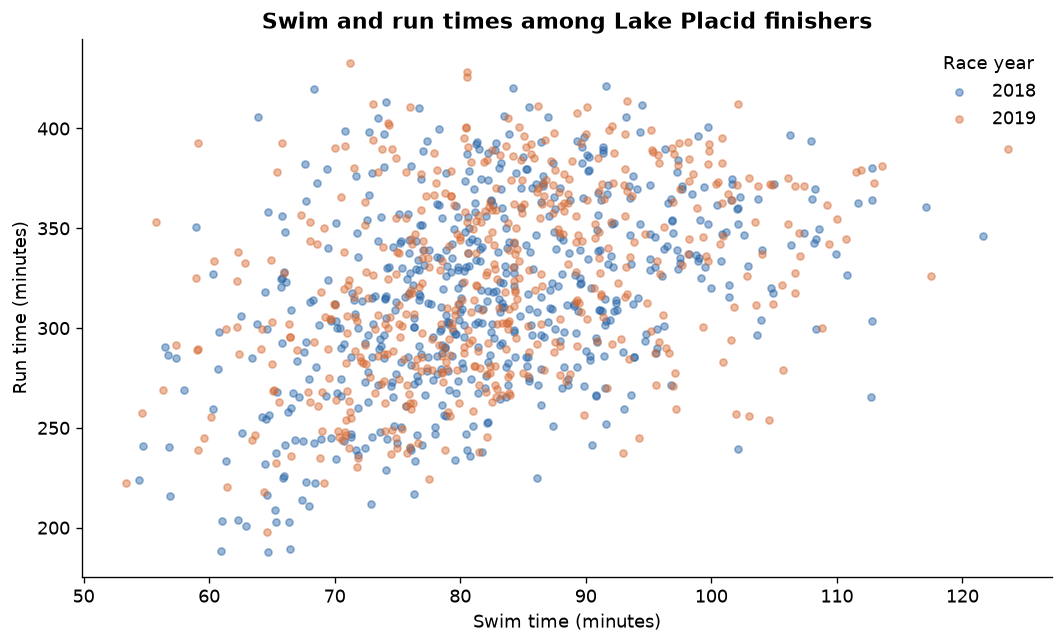

The sample Pearson correlation is **0.394**. The plot shows the association and its spread; it does not isolate training, age, weather, or other influences.

In [2]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for year, color in [(2018, BLUE), (2019, ORANGE)]:
    part = race.loc[race['Year'].eq(year)]
    ax.scatter(part['SwimTime'], part['RunTime'], s=18, alpha=.45, color=color, label=str(year))
ax.set(title='Swim and run times among Lake Placid finishers', xlabel='Swim time (minutes)', ylabel='Run time (minutes)')
ax.legend(title='Race year', frameon=False)
save_plot(fig, 'swim_run.png')
display(Markdown(f"The sample Pearson correlation is **{race['SwimTime'].corr(race['RunTime']):.3f}**. The plot shows the association and its spread; it does not isolate training, age, weather, or other influences."))

## 2. Overall finish time from bike time
Fit ordinary least squares with an intercept to all 1,105 records. The fitted line describes this sample. Overall time includes the bike segment, so part of the relationship is built into the definition of the outcome.

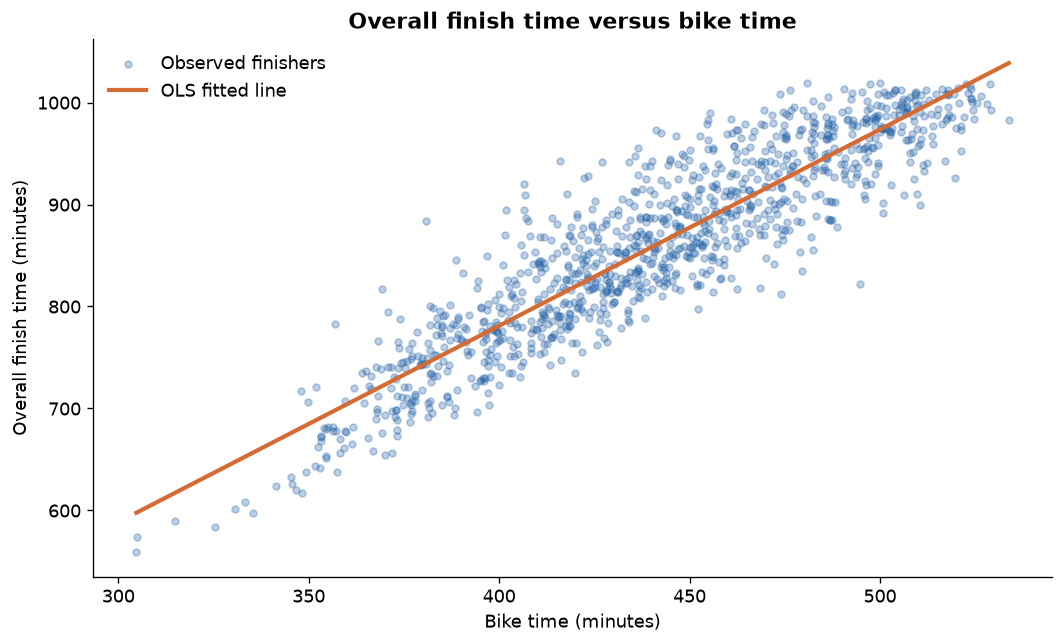

**Fitted equation:** OverallTime = 11.204 + 1.925 × BikeTime.

**Slope:** Each additional minute of bike time is associated with about 1.925 additional minutes of overall time on average in this sample. This is an association, not an intervention effect.

**Intercept:** The model gives 11.204 minutes at zero bike time. Zero is far outside the observed range (304.7–533.8 minutes), so the intercept is not a meaningful race prediction.

**R²:** 0.8281.

In [3]:
bike_model = fit_time(race, 'BikeTime')
grid = np.linspace(race['BikeTime'].min(), race['BikeTime'].max(), 150)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(race['BikeTime'], race['OverallTime'], s=17, alpha=.3, color=BLUE, label='Observed finishers')
ax.plot(grid, bike_model.predict(sm.add_constant(pd.DataFrame({'BikeTime': grid}), has_constant='add')), color=ORANGE, lw=2.5, label='OLS fitted line')
ax.set(title='Overall finish time versus bike time', xlabel='Bike time (minutes)', ylabel='Overall finish time (minutes)')
ax.legend(frameon=False)
save_plot(fig, 'bike_regression.png')
display(Markdown(f"**Fitted equation:** OverallTime = {bike_model.params['const']:.3f} + {bike_model.params['BikeTime']:.3f} × BikeTime.\n\n"
    f"**Slope:** Each additional minute of bike time is associated with about {bike_model.params['BikeTime']:.3f} additional minutes of overall time on average in this sample. This is an association, not an intervention effect.\n\n"
    f"**Intercept:** The model gives {bike_model.params['const']:.3f} minutes at zero bike time. Zero is far outside the observed range ({race['BikeTime'].min():.1f}–{race['BikeTime'].max():.1f} minutes), so the intercept is not a meaningful race prediction.\n\n"
    f"**R²:** {bike_model.rsquared:.4f}."))

## 3. Overall finish time from run time
Fit the same form of model with run time as its single predictor. As above, the target includes the predictor segment, so this is retrospective race analysis rather than a pre-race forecasting model.

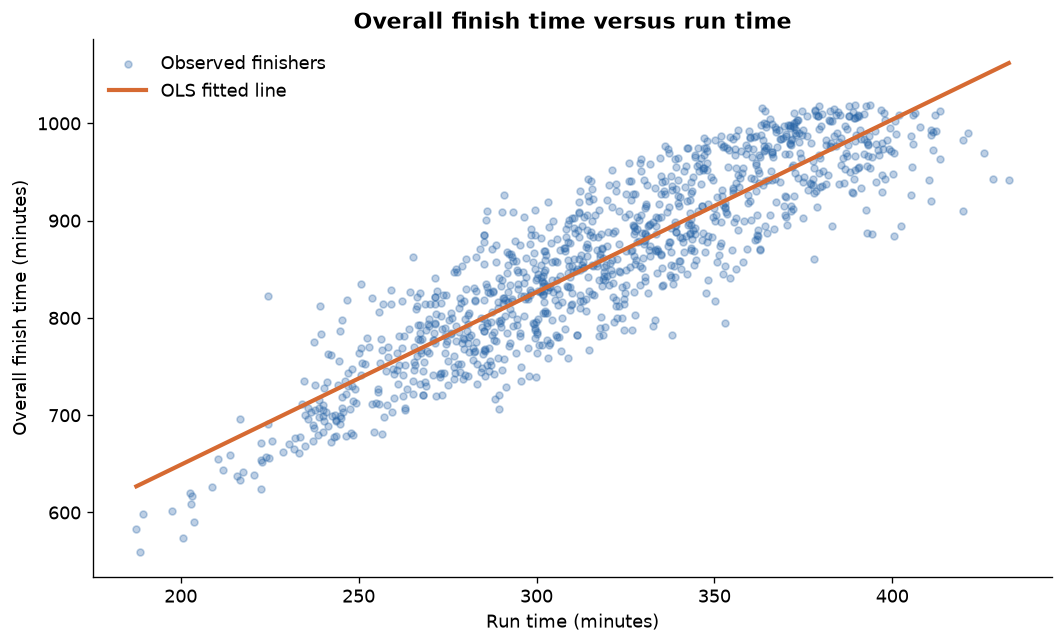

**Fitted equation:** OverallTime = 294.126 + 1.774 × RunTime.

**Slope:** One additional minute of run time is associated with about 1.774 additional minutes of overall time on average in this sample.

**Intercept:** At zero run time, the equation gives 294.126 minutes. Zero is outside the observed range (187.5–432.8 minutes), so this is an algebraic baseline rather than a realistic finish-time estimate.

**R²:** 0.8031.

In [4]:
run_model = fit_time(race, 'RunTime')
grid = np.linspace(race['RunTime'].min(), race['RunTime'].max(), 150)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(race['RunTime'], race['OverallTime'], s=17, alpha=.3, color=BLUE, label='Observed finishers')
ax.plot(grid, run_model.predict(sm.add_constant(pd.DataFrame({'RunTime': grid}), has_constant='add')), color=ORANGE, lw=2.5, label='OLS fitted line')
ax.set(title='Overall finish time versus run time', xlabel='Run time (minutes)', ylabel='Overall finish time (minutes)')
ax.legend(frameon=False)
save_plot(fig, 'run_regression.png')
display(Markdown(f"**Fitted equation:** OverallTime = {run_model.params['const']:.3f} + {run_model.params['RunTime']:.3f} × RunTime.\n\n"
    f"**Slope:** One additional minute of run time is associated with about {run_model.params['RunTime']:.3f} additional minutes of overall time on average in this sample.\n\n"
    f"**Intercept:** At zero run time, the equation gives {run_model.params['const']:.3f} minutes. Zero is outside the observed range ({race['RunTime'].min():.1f}–{race['RunTime'].max():.1f} minutes), so this is an algebraic baseline rather than a realistic finish-time estimate.\n\n"
    f"**R²:** {run_model.rsquared:.4f}."))

## 4. Compare the two regressions
Both models use the same outcome and the same full-sample records. Compare R² and in-sample root mean squared error (RMSE), keeping their training scope explicit. As an additional check, fit on 2018 only and evaluate on 2019. The latter is a single held-out race year, not broad external validation.

,Full-sample R²,Full-sample RMSE (min),2019 held-out RMSE (min),Training year,Test year,Training n,Test n
Predictor,,,,,,,
BikeTime,0.828,38.870,41.505,2018,2019,587,518
RunTime,0.803,41.602,43.462,2018,2019,587,518


**Full-sample comparison:** BikeTime explains more variation in overall time and has lower full-sample RMSE. **Held-out-year comparison:** BikeTime has lower error when a model fitted on 2018 is applied to 2019.

Neither model should be used to forecast a race before its component time is known. The outcome contains the predictor itself, observations include finishers only, and these two races do not represent all athletes or race conditions.

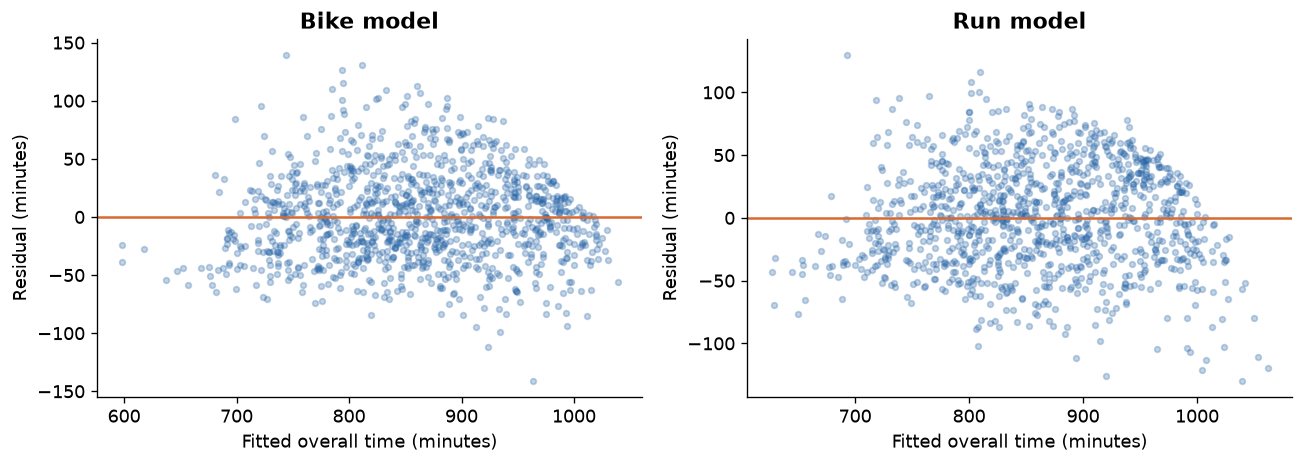

Residual plots check whether systematic patterns or unequal spread remain. OLS fit statistics alone do not establish all model assumptions or out-of-sample performance.

In [5]:
comparison = []
train, test = race.loc[race['Year'].eq(2018)], race.loc[race['Year'].eq(2019)]
for predictor, model in [('BikeTime', bike_model), ('RunTime', run_model)]:
    year_model = fit_time(train, predictor)
    prediction = year_model.predict(sm.add_constant(test[[predictor]], has_constant='add'))
    comparison.append({'Predictor': predictor, 'Full-sample R²': model.rsquared,
        'Full-sample RMSE (min)': np.sqrt(np.mean(model.resid**2)),
        '2019 held-out RMSE (min)': np.sqrt(np.mean((test['OverallTime'] - prediction)**2)),
        'Training year': 2018, 'Test year': 2019, 'Training n': len(train), 'Test n': len(test)})
comparison = pd.DataFrame(comparison).set_index('Predictor')
display(comparison.round(3))
winner = comparison['Full-sample R²'].idxmax()
held_out_winner = comparison['2019 held-out RMSE (min)'].idxmin()
display(Markdown(f"**Full-sample comparison:** {winner} explains more variation in overall time and has lower full-sample RMSE. **Held-out-year comparison:** {held_out_winner} has lower error when a model fitted on 2018 is applied to 2019.\n\n"
    "Neither model should be used to forecast a race before its component time is known. The outcome contains the predictor itself, observations include finishers only, and these two races do not represent all athletes or race conditions."))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, label, model in zip(axes, ['Bike model', 'Run model'], [bike_model, run_model]):
    ax.scatter(model.fittedvalues, model.resid, s=12, alpha=.28, color=BLUE)
    ax.axhline(0, color=ORANGE, lw=1.5)
    ax.set(title=label, xlabel='Fitted overall time (minutes)', ylabel='Residual (minutes)')
save_plot(fig, 'residual_diagnostics.png')
display(Markdown('Residual plots check whether systematic patterns or unequal spread remain. OLS fit statistics alone do not establish all model assumptions or out-of-sample performance.'))
comparison.to_csv(ROOT / 'data/model_comparison.csv')

## 5. Employment and phone contact counts
Create `job = 1` if either campus or off-campus employment is reported, and `job = 0` only when both are explicitly No. Unknown employment is not guessed. Compare the two groups with a boxplot and descriptive statistics. The public snapshot retains only the three fields needed for this calculation.

**Data check:** 67 survey responses; 65 usable for this comparison; 2 excluded for missing or invalid required values. Observed outliers are retained.

,n,mean,median,q1,q3,minimum,maximum
job,,,,,,,
No job,29,154.41,97.0,40.0,200.00,5.0,796.0
Has a job,36,241.28,175.0,95.5,326.75,5.0,981.0


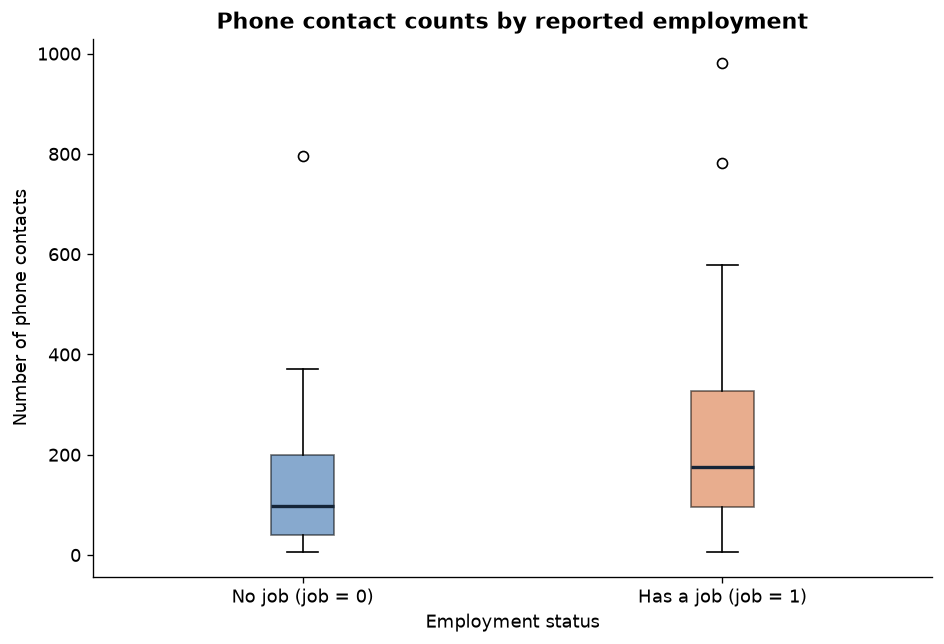

The observed medians are **97 contacts without a job** and **175 with a job**. The middle 50% ranges overlap. The groups show substantial within-group variability. A visual or median difference in this small convenience sample is not evidence that employment causes a change in contacts, nor a basis for generalizing to all students. No formal significance test is claimed.

In [6]:
survey = pd.read_csv(ROOT / 'data/survey_jobs_contacts.csv')
campus = survey['CampusJob'].astype('string').str.strip().str.lower()
off_campus = survey['OffCampusJob'].astype('string').str.strip().str.lower()
has_job = campus.eq('yes') | off_campus.eq('yes')
no_job = campus.eq('no') & off_campus.eq('no')
survey['job'] = np.select([has_job.fillna(False).to_numpy(dtype=bool), no_job.fillna(False).to_numpy(dtype=bool)], [1., 0.], default=np.nan)
survey['NumbContacts'] = pd.to_numeric(survey['NumbContacts'], errors='coerce')
valid = survey[['job', 'NumbContacts']].notna().all(axis=1) & survey['NumbContacts'].ge(0)
survey_analysis = survey.loc[valid, ['job', 'NumbContacts']].copy()
survey_analysis['job'] = survey_analysis['job'].astype(int)
display(Markdown(f"**Data check:** {len(survey)} survey responses; {len(survey_analysis)} usable for this comparison; {len(survey)-len(survey_analysis)} excluded for missing or invalid required values. Observed outliers are retained."))
group_summary = survey_analysis.groupby('job')['NumbContacts'].agg(n='count', mean='mean', median='median', q1=lambda x:x.quantile(.25), q3=lambda x:x.quantile(.75), minimum='min', maximum='max')
display(group_summary.round(2).rename(index={0:'No job',1:'Has a job'}))
fig, ax = plt.subplots(figsize=(8, 5.5))
groups = [survey_analysis.loc[survey_analysis['job'].eq(j), 'NumbContacts'] for j in [0,1]]
boxes = ax.boxplot(groups, tick_labels=['No job (job = 0)', 'Has a job (job = 1)'], patch_artist=True,
                   medianprops={'color':'#152538','linewidth':2})
for patch, color in zip(boxes['boxes'], [BLUE, ORANGE]):
    patch.set_facecolor(color); patch.set_alpha(.55)
ax.set(title='Phone contact counts by reported employment', xlabel='Employment status', ylabel='Number of phone contacts')
save_plot(fig, 'employment_contacts.png')
medians = group_summary['median']
lower_overlap = max(group_summary.loc[0,'q1'], group_summary.loc[1,'q1'])
upper_overlap = min(group_summary.loc[0,'q3'], group_summary.loc[1,'q3'])
display(Markdown(f"The observed medians are **{medians[0]:.0f} contacts without a job** and **{medians[1]:.0f} with a job**. "
    + ('The middle 50% ranges overlap. ' if lower_overlap <= upper_overlap else 'The middle 50% ranges do not overlap. ')
    + 'The groups show substantial within-group variability. A visual or median difference in this small convenience sample is not evidence that employment causes a change in contacts, nor a basis for generalizing to all students. No formal significance test is claimed.'))
group_summary.to_csv(ROOT / 'data/survey_group_summary.csv')

## 6. Passive and proactive ethics

Based on Bill Schmarzo's [author-published article](https://www.linkedin.com/pulse/ai-ethics-challenge-understanding-passive-versus-bill-schmarzo):

1. **Proactive ethics:** actively pursuing beneficial outcomes. **Passive ethics:** avoiding harm.
2. The **priest** and the **Levite** illustrate the passive approach in the Good Samaritan example.
3. **False.** Schmarzo argues that avoiding harm alone is insufficient; AI objectives should also pursue positive outcomes.

This is an attributed interpretation of the author's argument, rather than a universal definition of ethics. For this project, it motivates keeping uncertainty, data coverage, and limits of causal interpretation visible.

## Reproducibility and sources

- [Race CSV](https://webpages.charlotte.edu/mschuck1/classes/DTSC2301/Data/Ironman1819.csv): female Lake Placid finishers, 2018 and 2019; times in minutes. Included snapshot retains only year and four time measures.
- [Class-survey CSV](https://webpages.charlotte.edu/mschuck1/classes/DTSC2301/Data/DTSC2301FirstDaySurvey_Responses_Clean.csv): included snapshot retains only campus employment, off-campus employment, and contact counts. No names, timestamps, or unrelated respondent fields are included.
- [SCORE triathlon context](https://isle.stat.cmu.edu/SCORE/ironman_triathlon/).
- Bill Schmarzo, *AI Ethics Challenge: Understanding Passive versus Proactive Ethics* (2019), linked above.

Source snapshots were retrieved on October 27, 2026. This notebook uses included files for reproducibility, so rerunning it does not depend on source-site availability. Figures and summary CSVs are regenerated by execution. These are descriptive educational analyses, with limitations stated alongside their results.